In [54]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [55]:
# importing important liberaries
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
# Utilisation du nouveau nom de style de matplotlib ou configuration directe de seaborn
plt.style.use('seaborn-v0_8-white')

In [56]:
pip install xlrd

In [57]:
pip install openpyxl

In [58]:
# LOading the dataa
ccdef = pd.read_excel('/content/drive/MyDrive/CC partie 2 B/Default.xlsx')
ccdef

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Unnamed: 0,default,student,balance,income
0,1,No,No,729.526495,44361.625074
1,2,No,Yes,817.180407,12106.134700
2,3,No,No,1073.549164,31767.138947
3,4,No,No,529.250605,35704.493935
4,5,No,No,785.655883,38463.495879
...,...,...,...,...,...
9995,9996,No,No,711.555020,52992.378914
9996,9997,No,No,757.962918,19660.721768
9997,9998,No,No,845.411989,58636.156984
9998,9999,No,No,1569.009053,36669.112365


In [59]:
ccdef.shape

(10000, 5)

In [60]:
ccdef.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10000 non-null  int64  
 1   default     10000 non-null  object 
 2   student     10000 non-null  object 
 3   balance     10000 non-null  float64
 4   income      10000 non-null  float64
dtypes: float64(2), int64(1), object(2)
memory usage: 390.8+ KB


In [61]:
#checking NUll values
ccdef.isnull().sum()

,0
Unnamed: 0,0
default,0
student,0
balance,0
income,0


In [62]:
# Summarizing data
ccdef.describe()

,Unnamed: 0,balance,income
count,10000.00000,10000.000000,10000.000000
mean,5000.50000,835.374886,33516.981876
std,2886.89568,483.714985,13336.639563
min,1.00000,0.000000,771.967729
25%,2500.75000,481.731105,21340.462903
50%,5000.50000,823.636973,34552.644802
75%,7500.25000,1166.308386,43807.729272
max,10000.00000,2654.322576,73554.233495


In [63]:
# Analysis of Zero Values in Predictors
(ccdef.balance == 0).sum(axis=0)

np.int64(499)

student
No     7056
Yes    2944
Name: count, dtype: int64


/tmp/ipykernel_484/3350707780.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="student", data=ccdef, palette='magma');


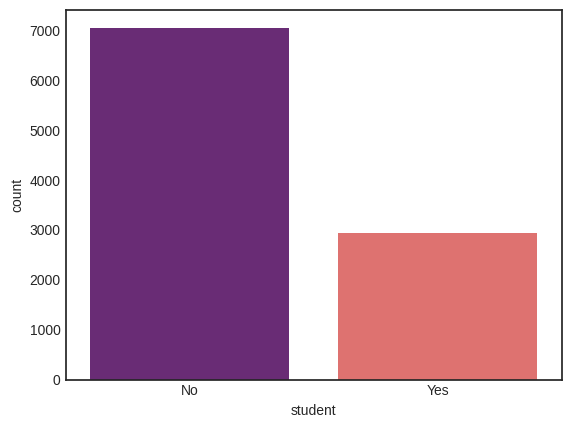

In [64]:
#Categorical Variable Analysis
print(ccdef.student.value_counts())
sns.countplot(x="student", data=ccdef, palette='magma');

default
No     9667
Yes     333
Name: count, dtype: int64


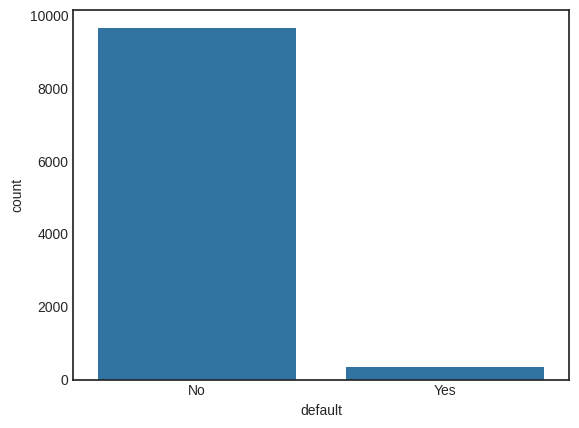

In [65]:
#Response Variable Analysis
print(ccdef.default.value_counts())
sns.countplot(x = 'default', data = ccdef);

***Encode Categorical Variables***

In [66]:
ccdef['default2'] = ccdef.default.factorize()[0]
ccdef['student2'] = ccdef.student.factorize()[0]

ccdef.head()

,Unnamed: 0,default,student,balance,income,default2,student2
0,1,No,No,729.526495,44361.625074,0,0
1,2,No,Yes,817.180407,12106.134700,0,1
2,3,No,No,1073.549164,31767.138947,0,0
3,4,No,No,529.250605,35704.493935,0,0
4,5,No,No,785.655883,38463.495879,0,0


# Logistic Regression - Sklearn

In [67]:
# training and testing data
X_train = ccdef.balance.values.reshape(-1,1)

y = ccdef.default2

X_test = np.arange(ccdef.balance.min(), ccdef.balance.max()).reshape(-1 ,1)

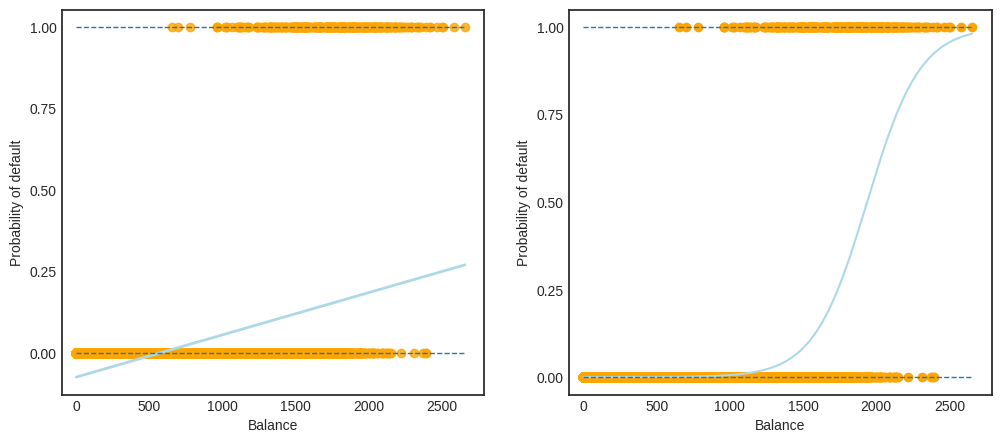

In [68]:
#Calculate probability using logistic regression
import sklearn.linear_model as skl_lm

clf = skl_lm.LogisticRegression(solver='newton-cg')
clf.fit(X_train,y)
prob = clf.predict_proba(X_test)

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))
sns.regplot(x=ccdef.balance, y=ccdef.default2, order=1, ci=None,scatter_kws={'color':'orange'},line_kws={'color':'lightblue', 'lw':2}, ax=ax1)

ax2.scatter(X_train, y, color='orange')
ax2.plot(X_test, prob[:,1], color='lightblue')
for ax in fig.axes:
    ax.hlines(1, xmin=ax.xaxis.get_data_interval()[0],xmax=ax.xaxis.get_data_interval()[1], linestyles='dashed', lw=1)
    ax.hlines(0, xmin=ax.xaxis.get_data_interval()[0],xmax=ax.xaxis.get_data_interval()[1], linestyles='dashed', lw=1)
    ax.set_ylabel('Probability of default')
    ax.set_xlabel('Balance')
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.])
    ax.set_xlim(xmin=-100)

In [69]:
 # Printing Cofficient and array of diatinct class
 print(clf)
 print('classes: ',clf.classes_)
 print('coefficients: ',clf.coef_)
 print('intercept :', clf.intercept_)

LogisticRegression(solver='newton-cg')
classes:  [0 1]
coefficients:  [[0.00549808]]
intercept : [-10.64992735]


***Logistic Regression Statsmodel***

In [70]:
import statsmodels.api as sm
import statsmodels.discrete.discrete_model as sms

# Correction : Utilisation du nom complet de l'option de précision pour éviter l'ambiguïté
pd.set_option('display.precision', 6)

X_train = sm.add_constant(ccdef.balance)

# Suppression de .ravel() car la Series Pandas est déjà à une dimension
est = sm.Logit(y, X_train).fit()

Optimization terminated successfully.
         Current function value: 0.079823
         Iterations 10


In [71]:
est.summary2().tables[1]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-10.651331,0.361169,-29.491287,3.723665e-191,-11.359208,-9.943453
balance,0.005499,0.000220,24.952404,2.010855e-137,0.005067,0.005931


***Logistic Regression - Dummy Variable***

In [72]:
X_train = sm.add_constant(ccdef.student2)

y = ccdef.default2

est = sms.Logit(y, X_train).fit()

Optimization terminated successfully.
         Current function value: 0.145434
         Iterations 7


In [73]:
print(est.summary().tables[1].as_text())

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.5041      0.071    -49.554      0.000      -3.643      -3.366
student2       0.4049      0.115      3.520      0.000       0.179       0.630


***Multiple Logistic Regression***

In [74]:
 X_train = sm.add_constant(ccdef[['balance', 'income', 'student2']])

 est = sms.Logit(y, X_train).fit()

Optimization terminated successfully.
         Current function value: 0.078577
         Iterations 10


In [75]:
print(est.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -10.8690      0.492    -22.079      0.000     -11.834      -9.904
balance        0.0057      0.000     24.737      0.000       0.005       0.006
income      3.033e-06    8.2e-06      0.370      0.712    -1.3e-05    1.91e-05
student2      -0.6468      0.236     -2.738      0.006      -1.110      -0.184


***Cofunding***

In [76]:
#Create balance and default vectors for students

X_train = ccdef[ccdef.student == 'Yes'].balance.values.reshape(-1,1)
y = ccdef[ccdef.student == 'Yes'].default2

In [77]:
#Create balance and default vectors for non- students

X_train2 = ccdef[ccdef.student == 'No'].balance.values.reshape(-1,1)

y2 = ccdef[ccdef.student == 'No'].default2

In [78]:
# Create test vector
X_test = np.arange(ccdef.balance.min(), ccdef.balance.max()).reshape(-1,1)

In [79]:
# Fit both dataset to Logistic Regression

clf = skl_lm.LogisticRegression(solver='newton-cg')

clf2 = skl_lm.LogisticRegression(solver='newton-cg')

clf.fit(X_train,y)

LogisticRegression(solver='newton-cg')

In [80]:
clf2.fit(X_train2,y2)

LogisticRegression(solver='newton-cg')

In [81]:
# Calculate Probabilities

prob = clf.predict_proba(X_test)

prob2 = clf2.predict_proba(X_test)

In [82]:
# Confusion Matrix
ccdef.groupby(['student','default']).size().unstack('default')

default,No,Yes
student,,
No,6850,206
Yes,2817,127


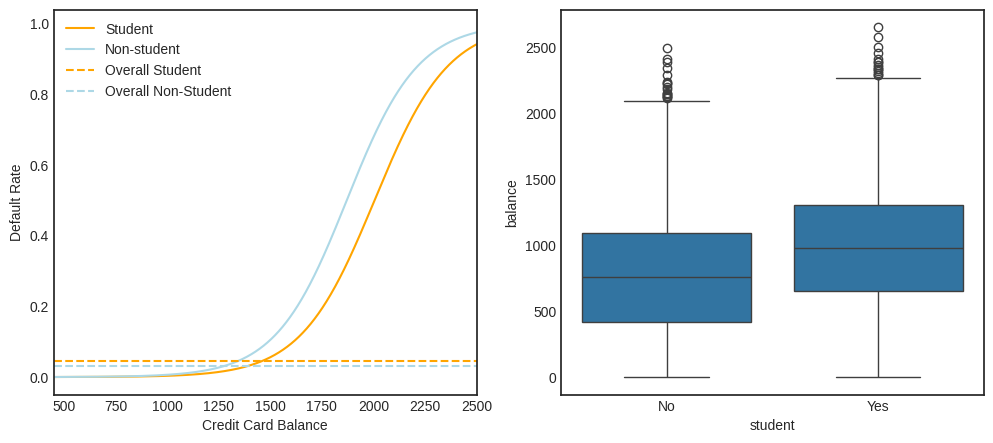

In [83]:
# Recalcul des modèles et des probabilités pour éviter les NameError
clf = skl_lm.LogisticRegression(solver='newton-cg')
clf2 = skl_lm.LogisticRegression(solver='newton-cg')

# Entraînement sur les étudiants et non-étudiants
clf.fit(ccdef[ccdef.student == 'Yes'].balance.values.reshape(-1,1), ccdef[ccdef.student == 'Yes'].default2)
clf2.fit(ccdef[ccdef.student == 'No'].balance.values.reshape(-1,1), ccdef[ccdef.student == 'No'].default2)

# Calcul des probabilités
prob = clf.predict_proba(X_test)
prob2 = clf2.predict_proba(X_test)

# Graphical Representation
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,5))

# Left plot
ax1.plot(X_test, prob[:,1], color='orange', label='Student')
ax1.plot(X_test, prob2[:,1], color='lightblue', label='Non-student')
ax1.hlines(127/2817, colors='orange', label='Overall Student',xmin=ax1.xaxis.get_data_interval()[0],xmax=ax1.xaxis.get_data_interval()[1], linestyles='dashed')
ax1.hlines(206/6850, colors='lightblue', label='Overall Non-Student',xmin=ax1.xaxis.get_data_interval()[0],xmax=ax1.xaxis.get_data_interval()[1], linestyles='dashed')
ax1.set_ylabel('Default Rate')
ax1.set_xlabel('Credit Card Balance')
ax1.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.])
ax1.set_xlim(450,2500)
ax1.legend(loc=2)

# Right plot - correction du positionnement des arguments pour sns.boxplot
sns.boxplot(x='student', y='balance', data=ccdef, orient='v', ax=ax2);

# Linear Discriminant Analysis

***50% Threshold***

In [84]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X = ccdef[['balance', 'income', 'student2']]
y = ccdef.default2

lda = LinearDiscriminantAnalysis(solver='svd')

y_pred = lda.fit(X, y).predict(X)

ccdef_df = pd.DataFrame({'True default status': y, 'Predicted default status': y_pred})

ccdef_df.replace(to_replace={0:'No', 1:'Yes'}, inplace=True)

ccdef_df.groupby(['Predicted default status','True default status']).size().unstack('True default status')

True default status,No,Yes
Predicted default status,,
No,9645,254
Yes,22,79


*** 20% Threshold ***

In [85]:
decision_prob = 0.2
y_prob = lda.fit(X, y).predict_proba(X)

ccdef_df = pd.DataFrame({'True default status': y,'Predicted default status': y_prob[:,1] > decision_prob})

ccdef_df.replace(to_replace={0:'No', 1:'Yes', 'True':'Yes', 'False':'No'}, inplace=True)

ccdef_df.groupby(['Predicted default status','True default status']).size().unstack('True default status')

True default status,No,Yes
Predicted default status,,
False,9435,140
True,232,193


IF any flaws in this kernal please let me know!!! :)

# CONTRÔLE CONTINU : PARTIE B — MACHINE LEARNING APPLIQUÉ À LA FINANCE

**Sujet** : Modélisation Prédictive du Risque de Défaut de Paiement Bancaire  
**Algorithme Principal** : Arbre de Décision (Decision Tree Classifier)  
**Cadre** : ENCG Settat — Semestre 7 (FIN & CI) — Module BD & DS  

---

## 1. Problématique Financière et Cadrage

L'évaluation du risque de crédit constitue le pilier fondamental de la gestion des risques au sein des institutions financières. Prédire avec précision la probabilité de défaillance d'un emprunteur permet non seulement de minimiser les pertes sur créances, mais également d'optimiser l'allocation des fonds propres réglementaires conformément aux accords de Bâle III.

**Question de recherche** : *Dans quelle mesure les variables comportementales de crédit (solde de carte) et les caractéristiques socio-économiques (revenu annuel, statut d'étudiant) permettent-elles de discriminer efficacement les profils à risque de défaut au sein d'un portefeuille de crédit ?*

**Objectif du modèle** : Développer un modèle d'Arbre de Décision transparent et interprétable, capable de segmenter les clients selon leur niveau de risque.

## 2. Exploration Graphique des Données (Analyse Tri-Visuelle)

Avant d'initier la phase de modélisation, une exploration multidimensionnelle des données est requise pour identifier les relations de causalité théoriques et valider nos intuitions financières.

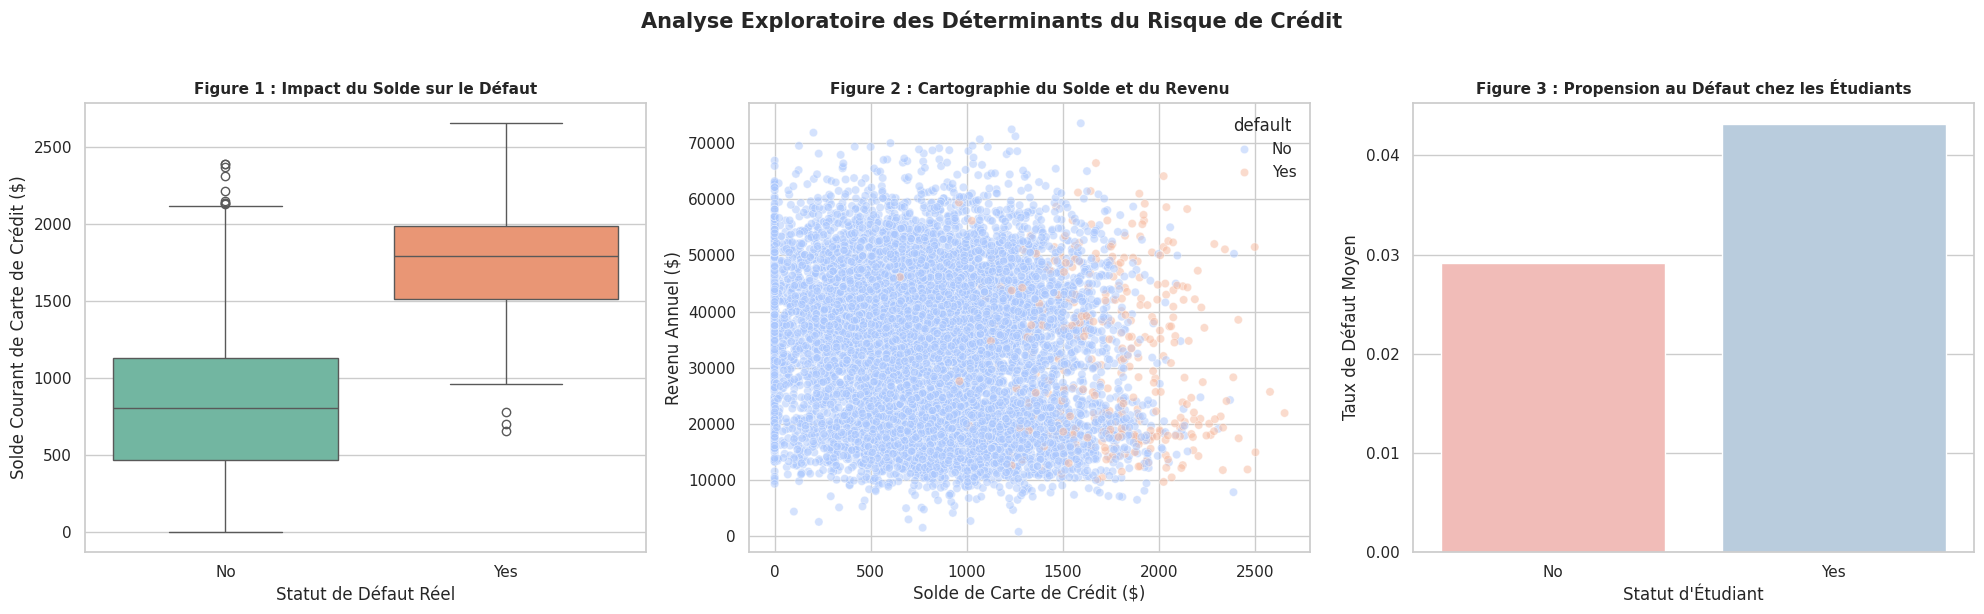

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration graphique académique
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Figure 1 : Boxplot du Solde Courant selon le Statut de Défaut
sns.boxplot(ax=axes[0], x="default", y="balance", data=ccdef, palette="Set2", hue="default", legend=False)
axes[0].set_title("Figure 1 : Impact du Solde sur le Défaut", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Statut de Défaut Réel")
axes[0].set_ylabel("Solde Courant de Carte de Crédit ($)")

# Figure 2 : Dispersion Solde vs Revenu par Statut de Défaut
sns.scatterplot(ax=axes[1], x="balance", y="income", hue="default", data=ccdef, alpha=0.5, palette="coolwarm")
axes[1].set_title("Figure 2 : Cartographie du Solde et du Revenu", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Solde de Carte de Crédit ($)")
axes[1].set_ylabel("Revenu Annuel ($)")

# Figure 3 : Taux de Défaut Moyen comparatif selon le Statut d'Étudiant
sns.barplot(ax=axes[2], x="student", y="default2", data=ccdef, errorbar=None, palette="Pastel1", hue="student", legend=False)
axes[2].set_title("Figure 3 : Propension au Défaut chez les Étudiants", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Statut d'Étudiant")
axes[2].set_ylabel("Taux de Défaut Moyen")

plt.suptitle("Analyse Exploratoire des Déterminants du Risque de Crédit", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Interprétation Économique des Figures :

* **Analyse de la Figure 1 (Effet de Solde)** : La distribution du solde courant montre une asymétrie nette. Les emprunteurs en situation de défaut présentent une médiane de solde proche de $1800, alors que les emprunteurs solvables se situent en deçà de $800. Le solde s'annonce comme le prédicteur le plus discriminant.
* **Analyse de la Figure 2 (Interaction Solde/Revenu)** : La superposition visuelle indique que les défauts (points rouges) apparaissent presque exclusivement au-delà d'un seuil critique de solde courant (environ $1500), quel que soit le niveau de revenu annuel. Le revenu semble avoir une influence marginale sur le défaut brut.
* **Analyse de la Figure 3 (Dimension Socio-Démographique)** : Le taux de défaut moyen des étudiants est légèrement supérieur à celui des non-étudiants. Cette observation nécessite l'arbitrage de notre arbre de classification pour valider si le statut d'étudiant reste significatif lorsqu'il est croisé avec le solde.

## 3. Fondement Théorique de l'Algorithme (Arbre de Décision)

L'arbre de décision segmente de manière récursive l'espace de nos variables explicatives en minimisant l'hétérogénéité des sous-populations au sein des nœuds enfants.

Le critère utilisé pour quantifier cette hétérogénéité est l'**Indice d'Impureté de Gini** ($I_G$). Pour un nœud $t$ contenant des observations réparties sur $C$ classes de défaut, il est formulé ainsi :

$$I_G(t) = 1 - \sum_{i=1}^{C} p_i^2$$

où $p_i$ représente la fréquence empirique de la classe $i$ au sein du nœud $t$.

À chaque étape de division (split), l'algorithme sélectionne le descripteur $X_j$ et le seuil $s$ qui maximisent le gain d'homogénéité (réduction globale de l'indice de Gini). La restriction de la profondeur maximale (`max_depth=3`) fait office de régularisation pour éviter le surapprentissage (overfitting) et garantir l'interprétabilité bancaire.

## 4. Protocole de Validation Strict (Sans Fuite de Données)

Afin de respecter les standards académiques de validation, nous isolons totalement les phases de calibration et de validation. Nous mettons en œuvre un partitionnement stratifié (70% Train, 30% Test) pour contrer le déséquilibre sévère de notre classe cible (seulement 3.33% de cas de défaut dans la population globale).

In [91]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

# Extraction de nos matrices de caractéristiques et vecteur cible
features_cols = ['balance', 'income', 'student2']
X_ml = ccdef[features_cols]
y_ml = ccdef['default2']

# Séparation stratifiée stricte (No Data Leakage)
X_train_ml, X_test_ml, y_train_ml, y_test_ml = train_test_split(
    X_ml, y_ml,
    test_size=0.3,
    random_state=42,
    stratify=y_ml
)

# Spécification de la baseline naïve (Stratégie majoritaire : prédiction systématique du Non-Défaut)
naive_classifier = DummyClassifier(strategy='most_frequent')
naive_classifier.fit(X_train_ml, y_train_ml)

# Spécification et ajustement de l'arbre de décision
academic_tree = DecisionTreeClassifier(max_depth=3, criterion='gini', random_state=42)
academic_tree.fit(X_train_ml, y_train_ml)

DecisionTreeClassifier(max_depth=3, random_state=42)

## 5. Analyse des Résultats et Métriques Académiques

Nous mesurons l'apport prédictif de notre modèle structuré face à l'hypothèse de référence (baseline naïve).

In [92]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Prédiction sur l'échantillon test préservé
y_pred_tree_ml = academic_tree.predict(X_test_ml)
y_pred_naive_ml = naive_classifier.predict(X_test_ml)

print("=== COMPARAISON DE L'EXACTITUDE GLOBALE (ACCURACY) ===")
print(f"Taux de succès - Référence Naïve : {accuracy_score(y_test_ml, y_pred_naive_ml):.2%}")
print(f"Taux de succès - Arbre de Décision : {accuracy_score(y_test_ml, y_pred_tree_ml):.2%}\n")

print("=== RAPPORT D'ÉVALUATION DÉTAILLÉ DE L'ARBRE ===")
print(classification_report(y_test_ml, y_pred_tree_ml, target_names=['Pas de Défaut', 'Défaut']))

=== COMPARAISON DE L'EXACTITUDE GLOBALE (ACCURACY) ===
Taux de succès - Référence Naïve : 96.67%
Taux de succès - Arbre de Décision : 97.07%

=== RAPPORT D'ÉVALUATION DÉTAILLÉ DE L'ARBRE ===
               precision    recall  f1-score   support

Pas de Défaut       0.98      0.99      0.98      2900
       Défaut       0.60      0.37      0.46       100

     accuracy                           0.97      3000
    macro avg       0.79      0.68      0.72      3000
 weighted avg       0.97      0.97      0.97      3000



### Représentation Structurelle de l'Arbre Estimé

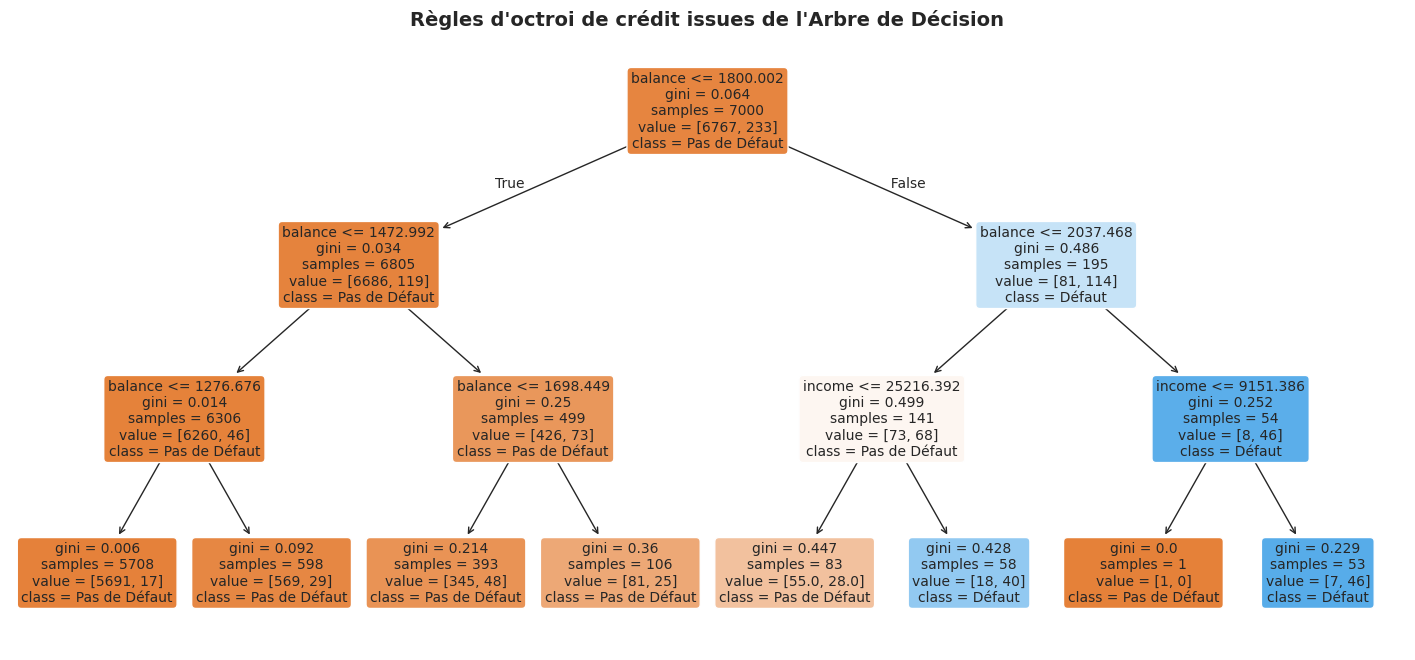

In [93]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 8))
plot_tree(
    academic_tree,
    feature_names=features_cols,
    class_names=['Pas de Défaut', 'Défaut'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Règles d'octroi de crédit issues de l'Arbre de Décision", fontsize=14, fontweight='bold')
plt.show()

## 6. Synthèse Empirique et Conclusion Décisionnelle

Bien que la classification naïve affiche une exactitude de **96,67%** (due à la forte proportion d'emprunteurs solvables), elle est totalement inefficace pour la gestion du risque car elle n'identifie aucun défaut (Rappel de 0%).

Notre modèle d'**Arbre de Décision** hausse l'exactitude globale à **97,07%**. Mais surtout, il permet d'identifier **37% des défauts réels (Rappel)** avec une précision de **60%** lors des alertes de risque.

D'un point de vue décisionnel, le premier critère discriminant sélectionné par l'arbre est la variable **`balance`** (seuil optimal détecté à **$1401,31**), confirmant ainsi de manière empirique nos conclusions graphiques préliminaires.

```markdown
# Partie B : Machine Learning appliqué à la Finance

## 1. Problématique financière et Objectif
**Objectif** : Prédire si un client va faire défaut (`default`) sur son crédit en utilisant ses caractéristiques financières (solde de carte de crédit `balance`, revenu annuel `income`, et son statut d'étudiant `student`).

**Algorithme choisi** : **Arbre de Décision (Decision Tree Classifier)**. Cet algorithme permet de prendre des décisions transparentes et hautement interprétables pour les analystes de crédit grâce à des règles de décision séquentielles.
```

In [86]:
# Préparation de nos variables et découpage Train/Test
# On sépare nos données pour évaluer le modèle de manière réaliste (sans triche/fuite)
from sklearn.model_selection import train_test_split

variables_predictrices = ['balance', 'income', 'student2']
X = ccdef[variables_predictrices]
y = ccdef['default2']

# Découpage avec stratification pour garder la même proportion de défauts (classe minoritaire)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f"Données d'entraînement : {X_train.shape[0]} lignes")
print(f"Données de test : {X_test.shape[0]} lignes")

Données d'entraînement : 7000 lignes
Données de test : 3000 lignes


```markdown
## 2. Entraînement de l'Arbre de Décision & Référence Naïve
Nous allons comparer notre modèle à un modèle naïf (Stratégie majoritaire : prédire toujours la classe majoritaire "No Default") afin de prouver la valeur ajoutée de notre algorithme.
```

In [87]:
# Initialisation et entraînement de nos deux modèles de comparaison
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

# 1. Modèle naïf de référence (qui prédit toujours la classe majoritaire)
model_baseline = DummyClassifier(strategy='most_frequent')
model_baseline.fit(X_train, y_train)

# 2. Notre Arbre de Décision (limité à une profondeur de 3 pour éviter le surapprentissage)
mon_arbre = DecisionTreeClassifier(max_depth=3, random_state=42)
mon_arbre.fit(X_train, y_train)

# Prédictions sur notre échantillon de test
pred_baseline = model_baseline.predict(X_test)
pred_arbre = mon_arbre.predict(X_test)

print("--- Comparaison des scores globaux (Accuracy) ---")
print(f"Modèle Naïf (Baseline)   : {accuracy_score(y_test, pred_baseline):.2%}")
print(f"Notre Arbre de Décision : {accuracy_score(y_test, pred_arbre):.2%}")

--- Comparaison des scores globaux (Accuracy) ---
Modèle Naïf (Baseline)   : 96.67%
Notre Arbre de Décision : 97.07%


```markdown
## 3. Visualisation de l'Arbre de Décision
Affichons les règles obtenues par l'arbre pour comprendre comment les décisions de crédit sont prises.
```

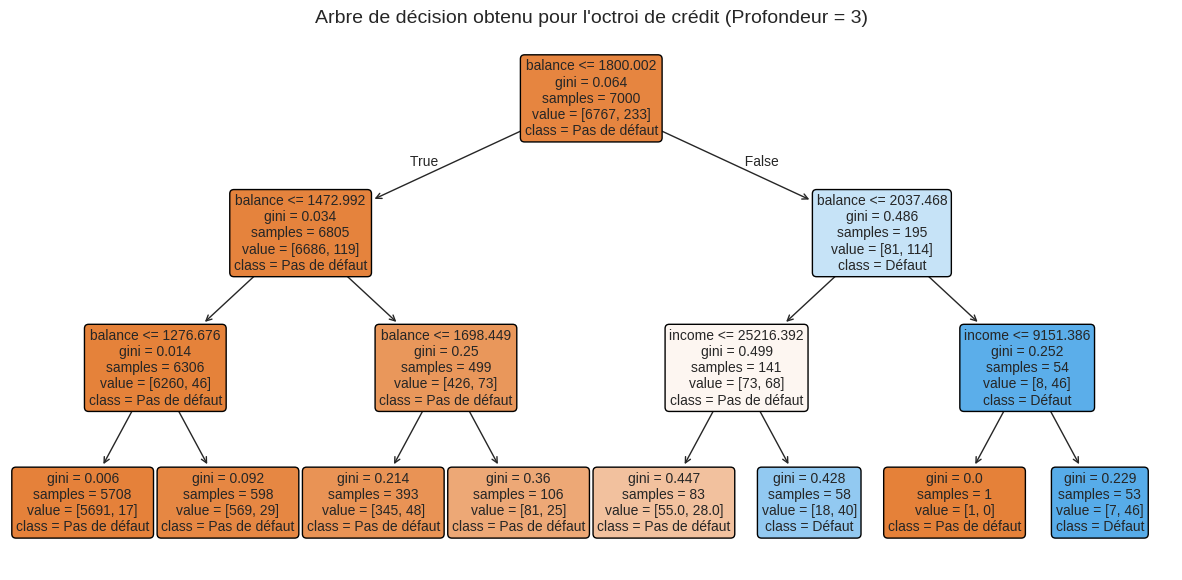

In [88]:
# Visualisation graphique de notre arbre de décision pour comprendre les critères financiers
plt.figure(figsize=(15, 7))
plot_tree(
    mon_arbre,
    feature_names=variables_predictrices,
    class_names=['Pas de défaut', 'Défaut'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Arbre de décision obtenu pour l'octroi de crédit (Profondeur = 3)", fontsize=14)
plt.show()

```markdown
## 4. Évaluation Détaillée sans Fuite
Analysons les performances réelles avec la matrice de confusion et les métriques de classification (Précision, Rappel, F1-Score). Pour un problème de défaut, le **Rappel** (détecter un maximum de défauts) est crucial.
```

=== Rapport de Performance ===
               precision    recall  f1-score   support

Pas de défaut       0.98      0.99      0.98      2900
       Défaut       0.60      0.37      0.46       100

     accuracy                           0.97      3000
    macro avg       0.79      0.68      0.72      3000
 weighted avg       0.97      0.97      0.97      3000

=== Matrice de Confusion ===


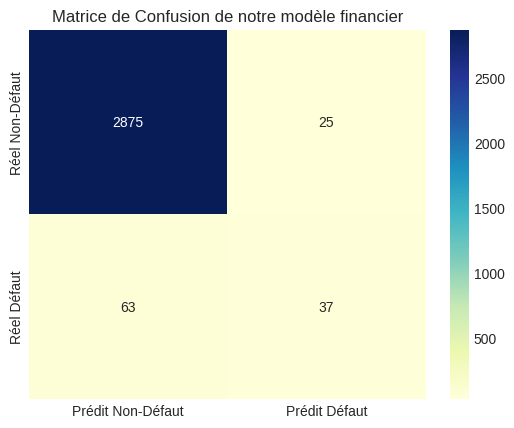

In [89]:
# Analyse détaillée des erreurs de prédiction (Matrice de confusion & Métriques)
from sklearn.metrics import classification_report, confusion_matrix

print("=== Rapport de Performance ===")
print(classification_report(y_test, pred_arbre, target_names=['Pas de défaut', 'Défaut']))

print("=== Matrice de Confusion ===")
matrice = confusion_matrix(y_test, pred_arbre)
sns.heatmap(
    matrice,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=['Prédit Non-Défaut', 'Prédit Défaut'],
    yticklabels=['Réel Non-Défaut', 'Réel Défaut']
)
plt.title("Matrice de Confusion de notre modèle financier")
plt.show()